In [1]:
# **Steps:** 1 Load and check - 2 Explore - 3 One row per home - 4 Same scale - 5 Try 1 to 8 segments - 6 Fit the final model - 7 Describe segments

# ---- SETUP: load the toolboxes ("import" = bring in ready-made tools written by other people) ----
import warnings                                    # a tool for controlling warning messages
import numpy as np                                 # numpy: tools for numbers and maths ("np" is its nickname)
import pandas as pd                                # pandas: tools for tables, like Excel ("pd" is its nickname)
import matplotlib.pyplot as plt                    # matplotlib: tools for drawing charts ("plt" is its nickname)
from sklearn.preprocessing import StandardScaler   # from the scikit-learn library, take the tool that rescales columns
from sklearn.mixture import GaussianMixture        # ...take the tool that fits the GMM (our clustering model)
from sklearn.metrics import silhouette_score, adjusted_rand_score   # ...take two scoring tools: "how well separated" and "how much two groupings agree"
from sklearn.decomposition import PCA              # ...take the tool that squeezes many columns down to 2 for a chart
from sklearn.exceptions import ConvergenceWarning  # ...take the name of a harmless warning that we want to hide

In [2]:
# Tell Python to hide that one kind of harmless warning so the output stays clean
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Two settings used throughout. (Capital letters are a habit for "settings you might change".)
DATA_FILE = "../data/raw/smart_home_energy_consumption_large.csv"   # the name of your data file. Text always goes in quotes.
SEED = 42    # a starting number for the computer's random choices. Same seed = same results every time.


In [4]:
# ## Step 1 - Load and check the data

# Read the CSV file into a table, and store the table in a box called df
df = pd.read_csv(DATA_FILE)

# Rename columns to shorter names. 
df = df.rename(columns={
    "Home ID": "home",                          # "Home ID" becomes "home"
    "Appliance Type": "appliance",              # "Appliance Type" becomes "appliance"
    "Energy Consumption (kWh)": "kwh",          # the energy column becomes "kwh"
    "Time": "time",                             # time of the reading
    "Date": "date",                             # date of the reading
    "Outdoor Temperature (°C)": "temp",         # outdoor temperature
    "Season": "season",                         # season label
    "Household Size": "household_size",         # number of people in the home
})

print("Rows, columns:", df.shape)                                   # .shape gives (number of rows, number of columns)
print("Number of homes:", df["home"].nunique())                     # pick the home column; .nunique() counts how many different values it has
print("Appliance types:", df["appliance"].nunique(), "->", sorted(df["appliance"].unique()))   # .unique() lists each different value once; sorted() puts them A to Z
print("Missing values per column:")                                 # a heading line
print(df.isna().sum())                                              # .isna() marks empty cells; .sum() counts them for each column
print("Duplicate rows:", df.duplicated().sum())                     # .duplicated() marks rows that repeat an earlier row; .sum() counts them
df.head()                                                           # show the first 5 rows, as a quick look


Rows, columns: (100000, 8)
Number of homes: 500
Appliance types: 10 -> ['Air Conditioning', 'Computer', 'Dishwasher', 'Fridge', 'Heater', 'Lights', 'Microwave', 'Oven', 'TV', 'Washing Machine']
Missing values per column:
home              0
appliance         0
kwh               0
time              0
date              0
temp              0
season            0
household_size    0
dtype: int64
Duplicate rows: 0


,home,appliance,kwh,time,date,temp,season,household_size
0,94,Fridge,0.20,21:12,2023-12-02,-1.0,Fall,2
1,435,Oven,0.23,20:11,2023-08-06,31.1,Summer,5
2,466,Dishwasher,0.32,06:39,2023-11-21,21.3,Fall,3
3,496,Heater,3.92,21:56,2023-01-21,-4.2,Winter,1
4,137,Microwave,0.44,04:31,2023-08-26,34.5,Summer,5


Average kWh per reading, by appliance:
appliance
Fridge              0.30
Lights              1.09
Dishwasher          1.10
Computer            1.10
Oven                1.10
Microwave           1.10
Washing Machine     1.10
TV                  1.10
Heater              3.49
Air Conditioning    3.50
Name: kwh, dtype: float64 

Average kWh per reading, by season:
season
Fall      1.498
Spring    1.511
Summer    1.495
Winter    1.496
Name: kwh, dtype: float64 

Average kWh per reading, by household size:
household_size
1    1.508
2    1.513
3    1.490
4    1.503
5    1.485
Name: kwh, dtype: float64 

Homes that report more than one household size: 500 of 500


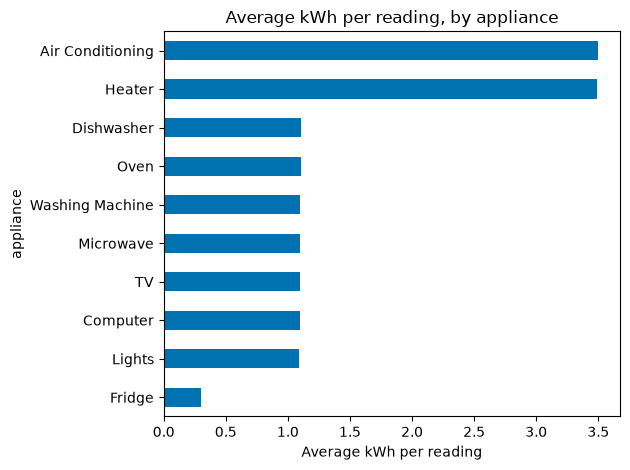

In [ ]:
#  2 - Explore the data

print("Average kWh per reading, by appliance:")     # a heading line
# Put rows into groups by appliance; look at the kwh column; average it; round to 2 decimals; sort from low to high. "\n" adds a blank line after.
print(df.groupby("appliance")["kwh"].mean().round(2).sort_values(), "\n")

print("Average kWh per reading, by season:")        # heading
print(df.groupby("season")["kwh"].mean().round(3), "\n")           # same idea, grouped by season, rounded to 3 decimals

print("Average kWh per reading, by household size:") # heading
print(df.groupby("household_size")["kwh"].mean().round(3), "\n")   # same idea, grouped by household size

# For each home, count how many DIFFERENT household sizes it reports
sizes_per_home = df.groupby("home")["household_size"].nunique()
# (sizes_per_home > 1) is True for homes reporting more than one size; .sum() counts the Trues; int() makes it a whole number; len() counts all homes
print("Homes that report more than one household size:", int((sizes_per_home > 1).sum()), "of", len(sizes_per_home))

# Draw a horizontal bar chart of average kWh for each appliance, sorted. "#0072B2" is a colour code (blue).
df.groupby("appliance")["kwh"].mean().sort_values().plot(kind="barh", color="#0072B2")   # barh = horizontal bars
plt.xlabel("Average kWh per reading")                    # label under the chart
plt.title("Average kWh per reading, by appliance")       # chart title
plt.tight_layout()                                       # tidy the spacing so nothing is cut off
plt.show()                                               # display the chart


In [ ]:
# 3 - Build one row per home
# **What this does:** the file has one row per reading (about 200 per home). Clustering needs one row per home, so we summarise each home with:
# - `avg_<appliance>`: the average kWh per reading for each appliance (10 columns, one per appliance)
#
# `make_features` is a small reusable recipe. We reuse it in the quality checks later.

# %%
# "def" starts a recipe called make_features. It takes a table (we call it "data") and will give back a new table.
def make_features(data):
    # For every (home, appliance) pair, work out the AVERAGE kWh per reading.
    # .unstack(...) turns the appliances into columns, so each home becomes one row.
    # If a home has no readings for an appliance, fill_value=0 puts a 0 there (it never used it).
    avg = data.groupby(["home", "appliance"])["kwh"].mean().unstack(fill_value=0)
    # Put "avg_" in front of every column name, e.g. Fridge becomes avg_Fridge.
    avg.columns = ["avg_" + name for name in avg.columns]
    # Hand the finished table back to whoever used the recipe
    return avg

# Use the recipe on our data, and keep the result in a box called features
features = make_features(df)
print("Table size (homes x features):", features.shape)   # rows = homes, columns = features (should be 500 x 10)
features.round(3).head()                                  # show the first 5 homes, numbers rounded to 3 decimals

Table size (homes x features): (500, 10)


,avg_Air Conditioning,avg_Computer,avg_Dishwasher,avg_Fridge,avg_Heater,avg_Lights,avg_Microwave,avg_Oven,avg_TV,avg_Washing Machine
home,,,,,,,,,,
1,3.378,1.144,1.007,0.274,3.468,1.238,1.197,1.115,0.867,1.301
2,3.342,1.002,1.232,0.302,3.221,1.076,1.032,1.237,1.138,1.210
3,3.652,1.064,1.060,0.318,3.827,1.149,1.129,1.282,0.978,1.195
4,3.365,1.172,1.132,0.351,3.243,1.002,1.035,0.838,1.081,1.098
5,3.586,1.143,1.185,0.340,3.279,1.035,1.020,1.258,0.747,1.065


In [7]:
# 4 - Put the features on the same scale

scaler = StandardScaler()                # create the rescaling tool (it has not done anything yet)
X = scaler.fit_transform(features)       # "fit" = learn each column's average and spread; "transform" = apply the rescaling. X is the rescaled table.
print("Scaled table size:", X.shape)                                                 # same number of rows and columns as before
print("Column averages (should be about 0):", X.mean(axis=0).round(2)[:4], "...")    # axis=0 means "down each column"; [:4] means "just the first four"
print("Column spreads  (should be about 1):", X.std(axis=0).round(2)[:4], "...")     # the spread of each column

Scaled table size: (500, 10)
Column averages (should be about 0): [-0. -0. -0. -0.] ...
Column spreads  (should be about 1): [1. 1. 1. 1.] ...


BIC for each number of segments (lower is better):
1    14545.0
2    14846.0
3    15123.0
4    15432.0
5    15715.0
6    16018.0
7    16287.0
8    16574.0
dtype: float64
Lowest BIC overall is at k = 1


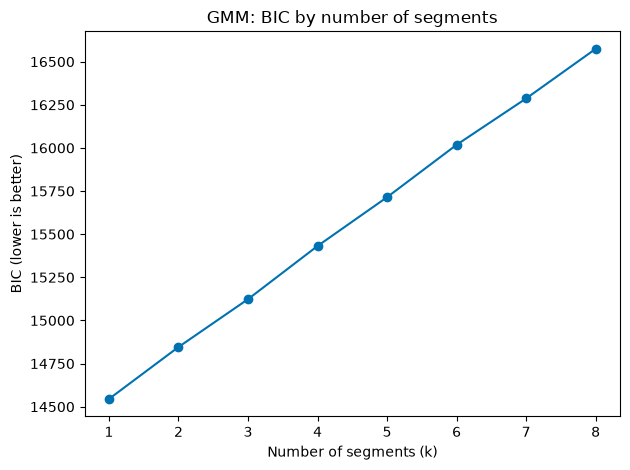

In [ ]:
# 5 - Try 1 to 8 segments and compare BIC
# **What this does:** a GMM looks for overlapping "clouds" of homes. We do not know how many clouds there are, so we try 1 to 8 and score each with **BIC**. BIC rewards a good fit but penalises extra clouds. **Lower BIC is better.**
#
# **What to look for:** a clear dip at some number of segments means that number fits best. A line that only rises means one group fits best.

K_MAX = 8                 # the biggest number of segments to try
bic_scores = {}           # an empty "dictionary": a list of label -> value pairs. We fill it in below.

# A LOOP: repeat the indented lines once for each k = 1, 2, ... 8 (range(1, 9) means 1 up to 8)
for k in range(1, K_MAX + 1):
    # Build a GMM with k clouds, then train it on our table. The lines inside ( ) are its settings.
    model = GaussianMixture(
        n_components=k,            # how many clouds (segments) to look for
        covariance_type="full",    # clouds may be stretched and tilted, not just round
        n_init=5,                  # try 5 different random starting points and keep the best
        reg_covar=1e-4,            # a tiny safety margin so the maths never breaks (1e-4 = 0.0001)
        max_iter=500,              # stop refining after 500 rounds
        random_state=SEED,         # use our fixed starting number so results repeat
    ).fit(X)                       # .fit(X) means "learn the clouds from table X"
    bic_scores[k] = model.bic(X)   # work out the BIC score for this model and store it in the dictionary under the label k

print("BIC for each number of segments (lower is better):")   # heading line
print(pd.Series(bic_scores).round(0))                         # turn the dictionary into a one-column table, round it, show it
print("Lowest BIC overall is at k =", min(bic_scores, key=bic_scores.get))   # find the k whose score is smallest
plt.plot(list(bic_scores.keys()), list(bic_scores.values()), "o-", color="#0072B2")
plt.xlabel("Number of segments (k)")
plt.ylabel("BIC (lower is better)")
plt.title("GMM: BIC by number of segments")
plt.tight_layout()
plt.show()

In [9]:
# 6 - Choose the number of segments and fit the final model
K_OVERRIDE = None

K = K_OVERRIDE or min(range(2, K_MAX + 1), key=lambda k: bic_scores[k])

# Train the final model with K clouds (same settings as Step 5)
final_model = GaussianMixture(
    n_components=K, covariance_type="full", n_init=5,
    reg_covar=1e-4, max_iter=500, random_state=SEED,
).fit(X)

raw_labels = final_model.predict(X)         # for each home: which cloud fits it best (0, 1, 2...)
raw_probs = final_model.predict_proba(X)    # for each home: the probability of belonging to EACH cloud

# The next four lines renumber the clouds so that Segment 1 is the biggest (easier to read)
order = np.argsort(-np.bincount(raw_labels, minlength=K))   # count the homes in each cloud, then list the clouds from biggest to smallest
new_id = np.empty(K, dtype=int)             # make an empty list of K whole numbers
new_id[order] = np.arange(K)                # fill it in: the biggest cloud gets 0, the next gets 1. Order = [1, 0] means: team 1 gets the number 0 (biggest), team 0 gets the number 1.  So new_id = [1, 0]   (read it as: "team 0 -> 1, team 1 -> 0")

# Give every house its NEW team number. Look up each house's old team on the board,
# then add 1 so we count from 1 instead of 0 (humans say "Segment 1", not "Segment 0").
#   raw_labels  [0, 1, 1, 0, 1, 1]
#   new_id says  0->1,  1->0   so the houses become [1, 0, 0, 1, 0, 0]
#   add 1                      so the final result is [2, 1, 1, 2, 1, 1]
#   Check: the 4 houses from the big team are now "Segment 1". It worked.
segment = new_id[raw_labels] + 1          


probs = raw_probs[:, order]                 # reorder the probability columns the same way (":" means "all rows")

results = features.copy()                                  # make a copy of the features table to add our results to
results["segment"] = segment                               # add a column holding each home's segment
results["membership_prob"] = probs.max(axis=1).round(3)    # add a column: the highest probability for each home (how sure the model is)
for j in range(K):                                         # repeat for each segment: j = 0, 1, ...
    results[f"prob_segment_{j + 1}"] = probs[:, j].round(3)   # add one probability column per segment; f"..." slips the number into the name

real_sil = silhouette_score(X, segment)     # score how clearly separated the segments are (-1 to 1)

print("Number of segments:", K)
print("Homes per segment:")
print(results["segment"].value_counts().sort_index())        # count homes in each segment, listed in order
print("Average membership probability:", results["membership_prob"].mean().round(3))   # average confidence across all homes
print("Homes with probability below 0.6 (borderline):", int((probs.max(axis=1) < 0.6).sum()))   # count homes whose best probability is under 0.6
print("Silhouette score:", round(real_sil, 3), "(above 0.5 is clear, below 0.25 is little structure)")
results.head()                                               # show the first 5 homes with their segment and probabilities

Number of segments: 2
Homes per segment:
segment
1    253
2    247
Name: count, dtype: int64
Average membership probability: 0.857
Homes with probability below 0.6 (borderline): 49
Silhouette score: 0.058 (above 0.5 is clear, below 0.25 is little structure)


,avg_Air Conditioning,avg_Computer,avg_Dishwasher,avg_Fridge,avg_Heater,avg_Lights,avg_Microwave,avg_Oven,avg_TV,avg_Washing Machine,segment,membership_prob,prob_segment_1,prob_segment_2
home,,,,,,,,,,,,,,
1,3.378261,1.144348,1.007222,0.274000,3.467727,1.237500,1.197222,1.115385,0.867222,1.301304,1,0.617,0.617,0.383
2,3.341765,1.002308,1.231667,0.301765,3.221200,1.076154,1.032500,1.237037,1.138333,1.210000,1,0.917,0.917,0.083
3,3.652500,1.063913,1.060000,0.318500,3.826667,1.148824,1.128857,1.282143,0.977500,1.195238,2,0.884,0.116,0.884
4,3.365000,1.171667,1.131667,0.351053,3.242778,1.001667,1.034615,0.837647,1.080952,1.097917,1,0.871,0.871,0.129
5,3.585789,1.143200,1.185263,0.340000,3.278636,1.035238,1.020000,1.258095,0.747143,1.065000,2,0.938,0.062,0.938


Segment 1 (253 homes): lower avg_Air Conditioning, higher avg_Dishwasher, higher avg_Lights
Segment 2 (247 homes): higher avg_Air Conditioning, lower avg_Dishwasher, lower avg_Lights


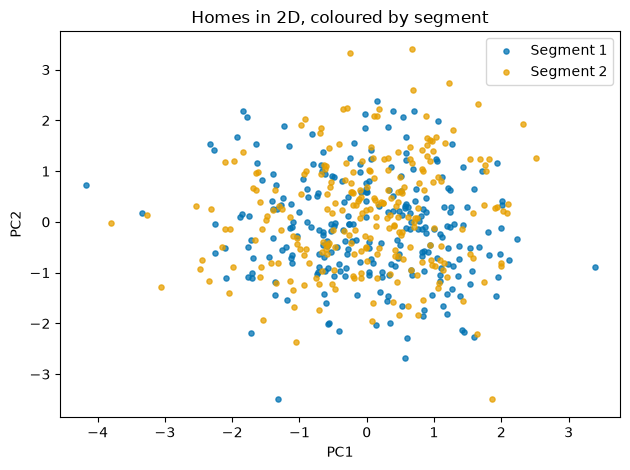

,avg_Air Conditioning,avg_Computer,avg_Dishwasher,avg_Fridge,avg_Heater,avg_Lights,avg_Microwave,avg_Oven,avg_TV,avg_Washing Machine
1,3.379,1.110,1.129,0.303,3.522,1.112,1.088,1.102,1.10,1.095
2,3.620,1.084,1.075,0.295,3.456,1.061,1.109,1.108,1.09,1.107


In [10]:
# Step 7 - Describe the segments
profile = features.groupby(segment).mean()                       # for each segment, the average of every feature
overall_mean, overall_spread = features.mean(), features.std()   # the average and spread of every feature across ALL homes

for seg in profile.index:                                        # repeat for each segment number
    z = (profile.loc[seg] - overall_mean) / overall_spread       # how far this segment is from the overall average, in units of spread
    top3 = z.reindex(z.abs().sort_values(ascending=False).index)[:3]   # sort by size of difference (ignoring +/-), keep the biggest 3
    words = [("higher " if v > 0 else "lower ") + name for name, v in top3.items()]   # for each: write "higher" if above average, else "lower", plus the feature name
    print(f"Segment {seg} ({int((segment == seg).sum())} homes): " + ", ".join(words))   # show the segment, its size, and the 3 phrases joined by commas

# Make a 2D picture of all homes
xy = PCA(n_components=2, random_state=0).fit_transform(X)        # squeeze the 10 columns down to 2 so we can plot them
colours = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#F0E442", "#7F7F7F"]   # a list of colour codes, one per segment
for seg in sorted(set(segment)):                                 # repeat for each segment
    mask = segment == seg                                        # True for homes in this segment, False for the others
    plt.scatter(xy[mask, 0], xy[mask, 1], s=14, alpha=0.75, color=colours[(seg - 1) % 8], label=f"Segment {seg}")   # draw those homes as dots (s = dot size, alpha = see-through level)
plt.xlabel("PC1"); plt.ylabel("PC2")                             # axis labels ("PC" = the 2 new squeezed-down dimensions)
plt.title("Homes in 2D, coloured by segment")                    # chart title
plt.legend()                                                     # show which colour is which segment
plt.tight_layout()                                               # tidy the spacing
plt.show()                                                       # display the chart

profile.round(3)                                                 # show the segment averages table, rounded

In [11]:
# Save the results table as a CSV file next to this notebook
results.to_csv("../data/processed/segments_gmm.csv")    # save the results table as a CSV file next to this notebook
print("Saved: data/processed/segments_gmm.csv")

Saved: data/processed/segments_gmm.csv


In [12]:
# 8 - Stability check: sort the homes twice, using different halves of the readings
rng = np.random.default_rng(SEED)                  # a random number generator, with a fixed start so results repeat
aris = []                                          
for _ in range(10):                                # repeat the test 10 times
    d = df.copy()                                  # work on a copy so the original table stays untouched
    d["rand"] = rng.random(len(d))                 # give every reading a random number
    d["place"] = d.groupby("home")["rand"].rank(pct=True)   # inside each home, rank its readings by that number (0 to 1)
    
    # first half of each home's readings -> half A, second half -> half B; then one row per home for each half
    fa = make_features(d[d["place"] <= 0.5]).reindex(index=features.index, columns=features.columns, fill_value=0)
    fb = make_features(d[d["place"] > 0.5]).reindex(index=features.index, columns=features.columns, fill_value=0)
    Xa = StandardScaler().fit_transform(fa)        # put half A on the same scale
    Xb = StandardScaler().fit_transform(fb)        # put half B on the same scale
    la = GaussianMixture(n_components=K, covariance_type="full", n_init=5, reg_covar=1e-4, max_iter=500, random_state=SEED).fit(Xa).predict(Xa)   # sort homes using half A
    lb = GaussianMixture(n_components=K, covariance_type="full", n_init=5, reg_covar=1e-4, max_iter=500, random_state=SEED).fit(Xb).predict(Xb)   # sort homes using half B
    aris.append(adjusted_rand_score(la, lb))       # how much do the two sorts agree? (1 = same, 0 = chance)

print("Stability (ARI) for each repeat:", np.round(aris, 3))
print("Average:", round(np.mean(aris), 3), "(near 1 = groups are stable, near 0 = groups change with the readings)")

Stability (ARI) for each repeat: [-0.001 -0.006 -0.002  0.    -0.002 -0.    -0.001 -0.003  0.004 -0.006]
Average: -0.002 (near 1 = groups are stable, near 0 = groups change with the readings)


In [14]:
# 9 - Agreement with K-means: do the two methods put the same homes together?
from sklearn.metrics import adjusted_rand_score

# Read the K-means segments (file made by the K-means notebook) and the GMM segments
km = pd.read_csv("../data/processed/home_segments.csv", index_col=0)
print(km.columns.tolist())          
seg_cols = [c for c in km.columns if any(w in c.lower() for w in ["segment", "cluster", "label"])]
print("Segment columns found:", seg_cols)
km_labels = km[seg_cols[0]]          

gmm_labels = results["segment"]     # the GMM segments from Step 6

# Keep the same homes in the same order in both
common = km_labels.index.intersection(gmm_labels.index)
a = km_labels.loc[common].values
b = gmm_labels.loc[common].values

real_ari = adjusted_rand_score(a, b)

# Baseline: shuffle the K-means labels 100 times and measure ARI each time
rng = np.random.default_rng(SEED)
shuffled = [adjusted_rand_score(rng.permutation(a), b) for _ in range(100)]

p_value = (1 + sum(s >= real_ari for s in shuffled)) / (1 + len(shuffled))

print("Real ARI (K-means vs GMM):", round(real_ari, 3))
print("Shuffled mean (maximum):", round(np.mean(shuffled), 3), f"({round(max(shuffled), 3)})")
print("Shuffled runs at least as high:", sum(s >= real_ari for s in shuffled), "of 100")
print("p-value:", round(p_value, 3))

['Air Conditioning', 'Computer', 'Dishwasher', 'Fridge', 'Heater', 'Lights', 'Microwave', 'Oven', 'TV', 'Washing Machine', 'n_readings', 'avg_kwh', 'cluster', 'segment_name']
Segment columns found: ['cluster', 'segment_name']
Real ARI (K-means vs GMM): 0.09
Shuffled mean (maximum): -0.0 (0.01)
Shuffled runs at least as high: 0 of 100
p-value: 0.01
